In [60]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random

In [61]:
def f(x):
    return 3 * x ** 2 - 4 * x + 5

In [62]:
f(3.0)

20.0

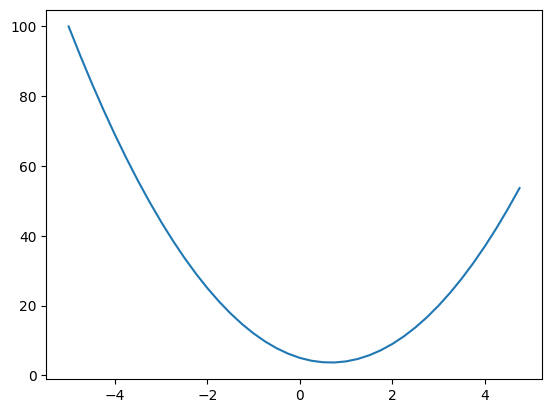

In [63]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [64]:
h = 0.00000001
x = 3.0
(f(x + h) - f(x))/ h

14.00000009255109

In [65]:
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [66]:
h = 0.0001

#inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a * b + c
a += h
d2 = a * b + c
print("d1", d1)
print("d2", d1)
print("slope", (d2 - d1)/h)

d1 4.0
d2 4.0
slope -3.000000000010772


In [77]:
class Value:

    def __init__(self, data, _children=(), _op='', label = ''):
        self.data = data
        self._backward = lambda : None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out


    def __pow__(self, other):
        assert isinstance(other, (int, float)), 'only supporting int/float powers for now'
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

        
    def __rmul__(self, other):
        return self * other

    def __radd__(self, other):  # other + self
        return self + other
    
    def __truediv__(self, other):
        return self * other ** - 1
    
    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (- other)
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1)/(math.exp(2*n) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()



In [68]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir' : 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # value node: a rectangle showing the data
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:   # only nodes produced by an operation get an op node
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        #connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [69]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1w1 + x2w2 + b
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

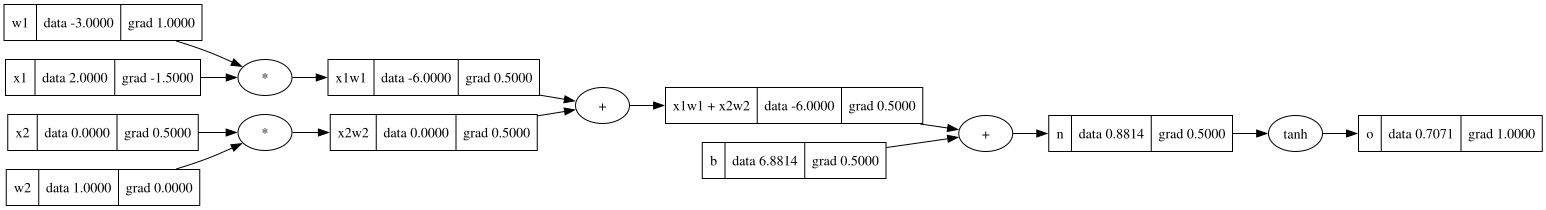

In [70]:
draw_dot(o)

<!-- n.grad = 0.5
x1w1x2w2.grad = 0.5
b.grad = 0.5
x1w1.grad = 0.5
x2w2.grad = 0.5
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad -->

In [71]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1w1 + x2w2 + b
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# ---
e = (2*n).exp()
o = (e - 1) / (e + 1)
# --- 
o.label = 'o'
o.backward()

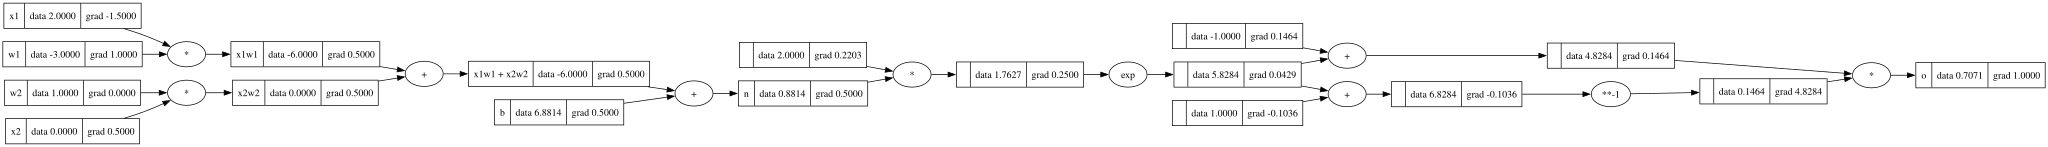

In [72]:
draw_dot(o)

In [73]:
import torch

x1 = torch.Tensor([2.0]).double()                            ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                            ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                           ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                            ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()              ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [74]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [112]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



In [115]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.6906390295008333)

In [119]:
n.parameters()

[Value(data=-0.8313869399996561),
 Value(data=-0.8011440117225317),
 Value(data=0.8579126107644417),
 Value(data=-0.14966023509080806),
 Value(data=-0.011484667740526033),
 Value(data=0.08207988191166593),
 Value(data=-0.09259635678545974),
 Value(data=-0.48857510657359904),
 Value(data=-0.7018658851659474),
 Value(data=0.4564187570728331),
 Value(data=-0.43653946047640013),
 Value(data=0.7007118398623386),
 Value(data=-0.20857515053755926),
 Value(data=-0.3247584071810621),
 Value(data=-0.05349165764484565),
 Value(data=-0.043106459225915605),
 Value(data=-0.5043758334184476),
 Value(data=-0.38603102625541674),
 Value(data=0.17298167230562211),
 Value(data=0.21203335682132218),
 Value(data=0.6627006608587953),
 Value(data=-0.2039219704839057),
 Value(data=-0.3218612940894636),
 Value(data=-0.33900652344593807),
 Value(data=0.07286009428535278),
 Value(data=0.037075944951232565),
 Value(data=-0.07314627713005883),
 Value(data=-0.7016900142311253),
 Value(data=0.3637984361737121),
 Valu

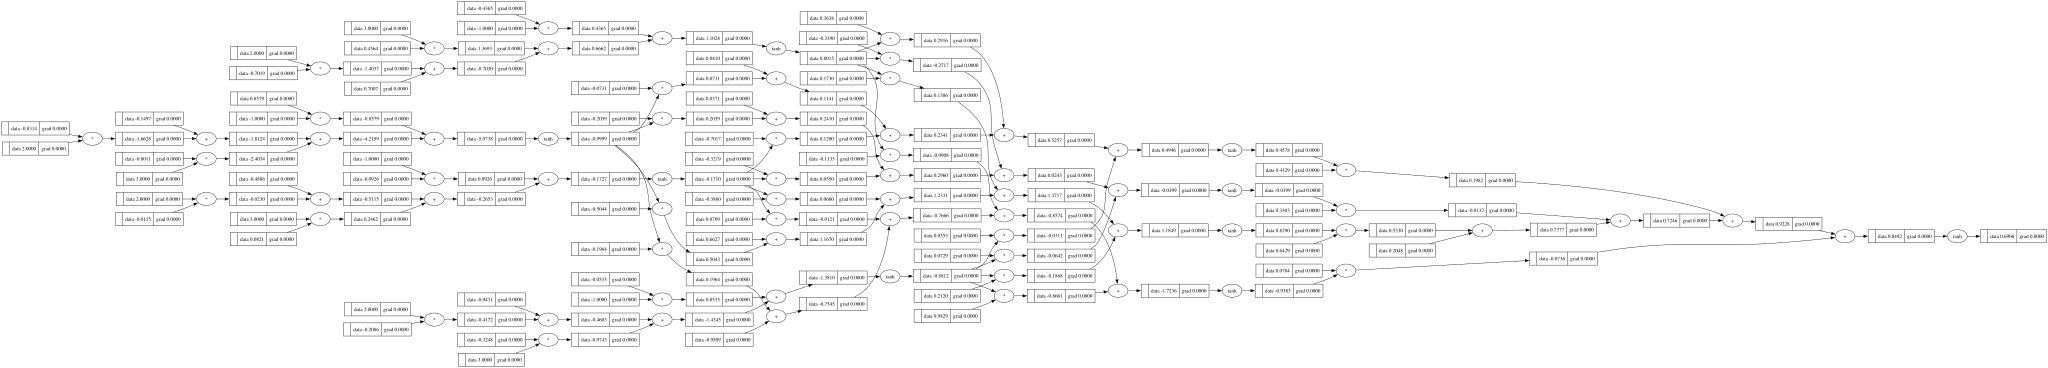

In [120]:
draw_dot(n(x))

In [121]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data=0.6906390295008333),
 Value(data=0.724664234268553),
 Value(data=0.7071724722038634),
 Value(data=0.7340369348974999)]

In [122]:
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=6.055345132882689)

In [530]:
for k in range(10):
    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k, loss.data)

0 0.0001576050628039428
1 0.0001575773727839261
2 0.0001575496953665442
3 0.0001575220305422488
4 0.00015749437830149776
5 0.0001574667386347587
6 0.0001574391115325112
7 0.00015741149698524553
8 0.00015738389498345606
9 0.0001573563055176535


In [529]:
loss.backward()

In [480]:
for p in n.parameters():
    p.data += 0.0007 * p.grad

In [483]:
ypred

[Value(data=0.9892082237278276),
 Value(data=-0.9997818776120265),
 Value(data=-0.9997818894466215),
 Value(data=0.9987776915214767)]

In [484]:
n.parameters()

[Value(data=-0.17295163808312497),
 Value(data=-0.242322348154829),
 Value(data=1.59025817747909),
 Value(data=0.6274152736604188),
 Value(data=0.6370146970056971),
 Value(data=-0.8232803296511203),
 Value(data=2.1178340461683023),
 Value(data=0.3195041580684897),
 Value(data=-0.7977079527475789),
 Value(data=-0.030131793818685623),
 Value(data=-2.1796140286078813),
 Value(data=-0.2573342048726236),
 Value(data=-0.886880064208566),
 Value(data=0.02835682061998666),
 Value(data=-0.7723583771798608),
 Value(data=-0.3601390637403235),
 Value(data=-0.8200568535332974),
 Value(data=-0.6275463601648799),
 Value(data=0.9302665551994832),
 Value(data=0.753778939487394),
 Value(data=-0.37808935771148333),
 Value(data=0.1390854699988562),
 Value(data=0.27674862515117926),
 Value(data=-0.13273523044020083),
 Value(data=-0.10421702438580081),
 Value(data=-0.06237475487480921),
 Value(data=-0.7849964794566782),
 Value(data=-0.8119059573701678),
 Value(data=1.4379068002661612),
 Value(data=0.2475565